# AQR Momentum Strategies

FINM 36700 HW6: AQR Momentum

Group: Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
FILE = "momentum_data.xlsx"

def load(sheet):
    return pd.read_excel(FILE, sheet_name=sheet, index_col="Date", parse_dates=True)

factors = load("factors (excess returns)")      
mom     = load("momentum (excess returns)")     
deciles = load("deciles (total returns)")       
size    = load("size_sorts (total returns)")    
rf      = load("risk-free rate")["RF"]



---
# 2. Investigating Momentum

Data: `data/momentum_data.xlsx`
- **Tab 1:** momentum factor $\tilde{r}^{\text{mom}}$ and Fama-French momentum $\tilde{r}^{\text{mom:FF}}$
- **Tab 2:** momentum decile portfolios (decile 1 = past losers, decile 10 = past winners)
- **Tab 3:** portfolios sorted on momentum and size: small winners ($r^{\text{momSU}}$), small losers ($r^{\text{momSD}}$), big winners ($r^{\text{momBU}}$), big losers ($r^{\text{momBD}}$)

FF construction:

$$\tilde{r}^{\text{mom:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - \tfrac{1}{2}\left(r^{\text{momBD}} + r^{\text{momSD}}\right)$$

## 2.1 Is momentum still profitable?

Subsamples: 1927–2024, 1927–1993, 1994–2008, 2009–2024.

### (a) 
Fill in Table 1 for $\tilde{r}^{\text{mom:FF}}$ across the four subsamples: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [15]:
def mom_stats(r, mkt, val, ann=12):
    return pd.Series({
        "Mean":        r.mean() * ann,
        "Vol":         r.std() * np.sqrt(ann),
        "Sharpe":      r.mean() / r.std() * np.sqrt(ann),
        "Skewness":    r.skew(),
        "Corr to MKT": r.corr(mkt),
        "Corr to HML": r.corr(val),
    })

periods = {
    "1927–2024": ("1927", "2024"),
    "1927–1993": ("1927", "1993"),
    "1994–2008": ("1994", "2008"),
    "2009–2024": ("2009", "2024"),
}

table1 = {}
for name in periods:
    start, end = periods[name]
    table1[name] = mom_stats(mom["UMD"].loc[start:end],
                             factors["MKT"].loc[start:end],
                             factors["HML"].loc[start:end])

table1 = pd.DataFrame(table1).T
table1.style.format({"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}",
                     "Skewness": "{:.2f}", "Corr to MKT": "{:.2f}", "Corr to HML": "{:.2f}"})

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
1927–2024,7.39%,16.27%,0.45,-3.07,-0.35,-0.41
1927–1993,8.81%,16.05%,0.55,-3.91,-0.37,-0.50
1994–2008,10.27%,17.54%,0.59,-0.60,-0.24,-0.12
2009–2024,-1.29%,15.80%,-0.08,-2.69,-0.37,-0.32


### (b) 
Has momentum changed much across the subsamples?

**Answer:**

Yes, momentum has changed across the subsamples, mainly in its reward rather than its risk.

The first two subsamples show mean returns of 8.81% and 10.27% and Sharpe ratios of 0.55 and 0.59. In particular, the second subsample (1994–2008) comes after the publication of Jegadeesh and Titman (1993) and Asness (1994), indicating that momentum wasn't arbitraged away after publication. From 2009 to 2024, however, the strategy had a negative mean return of −1.29% and a Sharpe of −0.08. The full-sample mean return is 7.39%.

The risk side has changed much less. Volatility is roughly 16–18% in every subsample, and the correlations with the market and value stay negative throughout. Skewness is strongly negative in every period except 1994–2008 (−0.60); it becomes severe again in 2009–2024 (−2.69), reflecting the 2009 momentum crash. So the premium has disappeared recently while the crash risk has not.

### (c)
Does the data support AQR's case that momentum belongs in the ideal portfolio? Would it still be valuable if transaction costs pushed mean returns near zero?

**Answer:**

Yes. The long-run full-sample Sharpe of 0.45, together with a negative correlation with the market (−0.35) and value (−0.41), indicates that it would be looked at favourably by the optimizer, since it has a positive premium that hedges the other factors' exposures.

Even if transaction costs pushed the mean returns towards zero, momentum would still be valuable in an ideal portfolio, as its weight depends on Σ⁻¹μ, not on μ alone. A zero-mean asset that is negatively correlated with MKT and HML would decrease portfolio variance, raising the Sharpe of the combined portfolio.

The main caveat is crash risk. Correlations do not capture momentum's strongly negative skewness (−3.07 over the full sample), and the most recent subsample has a negative mean, so the case for momentum rests on its diversification benefit rather than on a reliable standalone premium.

## 2.2 Is a long-only momentum implementation valuable?

Sample: 1994–2024.

Long-only (FF style):

$$\tilde{r}^{\text{momU:FF}} = \tfrac{1}{2}\left(r^{\text{momBU}} + r^{\text{momSU}}\right) - r^f$$

### (a)
Fill in Table 2 comparing long-short $\tilde{r}^{\text{mom:FF}}$ and long-only $\tilde{r}^{\text{momU:FF}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [16]:
s, e = "1994", "2024"
mkt, hml = factors["MKT"].loc[s:e], factors["HML"].loc[s:e]

long_short = mom["UMD"].loc[s:e]
long_only  = (0.5 * (size["BIG HiPRIOR"] + size["SMALL HiPRIOR"]) - rf).loc[s:e]

table2 = pd.DataFrame({
    "Long-short (mom:FF)": mom_stats(long_short, mkt, hml),
    "Long-only (momU:FF)": mom_stats(long_only, mkt, hml),
    "MKT":                 mom_stats(mkt, mkt, hml),
}).T

table2.style.format({"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}",
                     "Skewness": "{:.2f}", "Corr to MKT": "{:.2f}", "Corr to HML": "{:.2f}"})

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
Long-short (mom:FF),4.31%,16.72%,0.26,-1.46,-0.31,-0.21
Long-only (momU:FF),11.61%,17.80%,0.65,-0.44,0.90,-0.12
MKT,8.98%,15.54%,0.58,-0.60,1.00,-0.09


### (b)
Is long-only momentum as attractive as long-short on mean, volatility and Sharpe ratio?

**Answer:**

On a standalone basis, long-only momentum looks more attractive than long-short momentum, with a mean and vol of 11.61% and 17.80% against 4.31% and 16.72%, for a Sharpe of 0.65 vs 0.26.

However, most of that comes from market exposure rather than momentum. The market itself earned 8.98% with a Sharpe of 0.58 over the same period, so long-only momentum adds only about 2.6% per year in mean and 0.07 in Sharpe over simply holding the market. The relevant comparison for a long-only product is therefore against the market, and on that basis the improvement is modest.

### (c)
Is long-only momentum as diversifying against the market and value premia?

**Answer:**

However, the long-only momentum does not serve the purpose of diversifying against the market, with a correlation to MKT of 0.90 vs the long-short correlation of -0.31. The correlation to HML also weakens from −0.21 to −0.12. Therefore, an optimizer for a portfolio would most likely not prefer the long-only portfolio over the long-short portfolio, despite its higher Sharpe.

### (d)
Plot the cumulative product of $(1+\tilde{r}^{\text{mom:FF}})$ and $(1+\tilde{r}^{\text{momU:FF}})$ over 1994–2024.

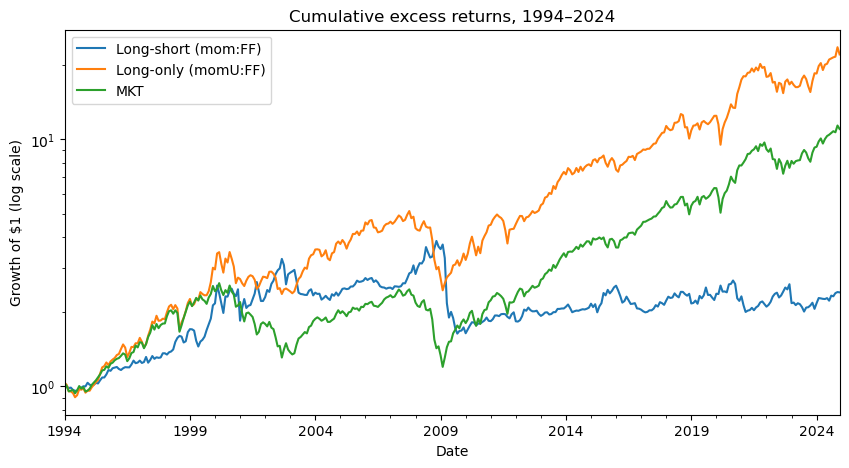

In [20]:
cum = pd.DataFrame({
    "Long-short (mom:FF)": (1 + long_short).cumprod(),
    "Long-only (momU:FF)": (1 + long_only).cumprod(),
    "MKT":                 (1 + mkt).cumprod(),
})

cum.plot(logy=True, figsize=(10, 5), title="Cumulative excess returns, 1994–2024")
plt.ylabel("Growth of $1 (log scale)")
plt.show()

## 2.3 Is momentum data mining or a robust strategy?

Sample: 1994–2024. Long-short constructions, equal-weighted across included deciles:
- $\tilde{r}^{\text{momD1}}$: top 1 decile minus bottom 1 decile
- $\tilde{r}^{\text{momD3}}$: top 3 deciles minus bottom 3 deciles
- $\tilde{r}^{\text{momD5}}$: top 5 deciles minus bottom 5 deciles

### (a)
Fill in Table 3 for $\tilde{r}^{\text{momD1}}$, $\tilde{r}^{\text{momD3}}$, $\tilde{r}^{\text{momD5}}$: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$, corr. to $\tilde{r}^{v}$.

In [22]:
deciles.columns = [f"D{i}" for i in range(1, 11)]
d = deciles.loc[s:e]

mom_d1 = d["D10"] - d["D1"]
mom_d3 = d[["D8", "D9", "D10"]].mean(axis=1) - d[["D1", "D2", "D3"]].mean(axis=1)
mom_d5 = d[["D6", "D7", "D8", "D9", "D10"]].mean(axis=1) - d[["D1", "D2", "D3", "D4", "D5"]].mean(axis=1)

table3 = pd.DataFrame({
    "momD1":  mom_stats(mom_d1, mkt, hml),
    "momD3":  mom_stats(mom_d3, mkt, hml),
    "momD5":  mom_stats(mom_d5, mkt, hml),
    "mom:FF": mom_stats(long_short, mkt, hml),
}).T

table3.style.format({"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}",
                     "Skewness": "{:.2f}", "Corr to MKT": "{:.2f}", "Corr to HML": "{:.2f}"})

,Mean,Vol,Sharpe,Skewness,Corr to MKT,Corr to HML
momD1,8.10%,29.96%,0.27,-1.30,-0.32,-0.24
momD3,2.97%,19.37%,0.15,-1.34,-0.36,-0.21
momD5,1.73%,13.43%,0.13,-1.42,-0.35,-0.21
mom:FF,4.31%,16.72%,0.26,-1.46,-0.31,-0.21


### (b)
Do the tradeoffs across the 1-, 3- and 5-decile constructions match the theory from lecture?

**Answer:**

Yes, the tradeoffs across the constructions match the theory from lecture: the narrower the selection, the higher the mean, but also the higher the volatility, due to fewer diversification benefits. As seen above, the more selective a portfolio is, the higher its mean and volatility (D1 vs D5 is 8.1% vs 1.7% mean and 30% vs 13% vol). Given that the strength of the momentum effect changes smoothly and predictably, this argues against the idea that it is the result of data mining.

### (c)
Should AQR's retail product use a 1-decile or a 5-decile construction?

**Answer:**

On paper, the 1-decile construction looks best: it has by far the highest Sharpe (0.27, vs 0.15 and 0.13 for momD3 and momD5, respectively) while having practically the same diversification benefits against MKT and HML.

For a retail product, however, we would not recommend it. Its volatility is 30%, nearly twice that of the market, which is hard for retail investors to hold through drawdowns. It also has the highest turnover, since stocks move in and out of the extreme deciles more often, so its Sharpe advantage, which is measured before trading costs, is the one most exposed to costs. The 5-decile construction goes too far in the other direction, diluting the signal to a mean of only 1.7%. A middle construction such as the 3-decile (top third) balances signal strength against trading costs and volatility.

### (d)
Compare $\tilde{r}^{\text{momD3}}$ with the FF construction in Table 2. Both are 3-decile long-short, but FF separates small and large stocks.

**Answer:**

The FF construction has a higher mean (4.3% vs. 3.0%) and Sharpe (0.26 vs. 0.15) with lower volatility (16.7% vs. 19.4%). The size split is what makes the difference, since the deciles are value-weighted and therefore momD3 is dominated by large caps. FF, on the other hand, gives small stocks 50% of the weight.

## 2.4 Does implementation require trading many small stocks?

Sample: 1994–2024.
- Small-stock momentum: $r^{\text{momS}} = r^{\text{momSU}} - r^{\text{momSD}}$
- Big-stock momentum: $r^{\text{momB}} = r^{\text{momBU}} - r^{\text{momBD}}$

### (a)
Fill in Table 4 for all stocks, small stocks and large stocks: mean, volatility, Sharpe, skewness, corr. to $\tilde{r}^{m}$.

In [23]:
z = size.loc[s:e]

mom_small = z["SMALL HiPRIOR"] - z["SMALL LoPRIOR"]
mom_big   = z["BIG HiPRIOR"] - z["BIG LoPRIOR"]

table4 = pd.DataFrame({
    "All stocks":   mom_stats(long_short, mkt, hml),
    "Small stocks": mom_stats(mom_small, mkt, hml),
    "Large stocks": mom_stats(mom_big, mkt, hml),
}).T.drop(columns="Corr to HML")

table4.style.format({"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}",
                     "Skewness": "{:.2f}", "Corr to MKT": "{:.2f}"})

,Mean,Vol,Sharpe,Skewness,Corr to MKT
All stocks,4.31%,16.72%,0.26,-1.46,-0.31
Small stocks,6.14%,16.91%,0.36,-1.80,-0.31
Large stocks,2.46%,18.23%,0.14,-0.87,-0.28


### (b)
Is momentum's attractiveness driven mostly by small stocks, or does large-stock momentum still offer comparable risk-adjusted excess returns?

**Answer:**

As shown by the table above, momentum's attractiveness is driven mostly by small stocks. Small stocks momentum has a mean of 6.14% with a Sharpe of 0.36, versus 2.46% and 0.14 for large stocks, with similar volatility (16.91% vs 18.23%), so the large gap comes from returns rather than risk.

Large-stock momentum does not offer comparable risk-adjusted excess returns. However, it does have a smaller crash risk (skewness of -0.87 vs -1.80).

## 2.5 Conclusion

Assess the AQR retail product. Does it capture the key features of the FF momentum construction? What modifications would you suggest?

**Answer:**

AQR's retail product is a long-only portfolio of roughly the top third of large- and mid-cap stocks by momentum, similar to a long-only version of momD3. We believe it does well in capturing some key features of the FF construction, but it departs from FF in two ways that are costly for investors' risk-adjusted returns.

First, the fact that it is long-only and thus drops the short leg leads to a 0.90 correlation with the market (as shown in part 2.2), versus -0.31 for long-short, so it loses most of the diversification benefit, which was the argument we made in favour of momentum in 2.1.

Second, given it is value-weighted, it gives most of the weight to large caps and does not benefit from the attractiveness of small-stock momentum, as large-cap momentum has less than half the Sharpe of small-stock momentum (0.14 vs 0.36). Therefore, the retail product does not capture the full effect of the FF 50-50 large-cap / small-cap construction.

However, one thing that the product does well is that it rebalances every quarter and uses a top-third cutoff, which reduces turnover and trading costs. Therefore, comparing it with the FF momentum construction must also take this into account, as FF momentum would have much higher trading costs, making the comparison unfair.

One suggestion we would make is to allow for a limited short leg (for example a 130/30 structure, as a 30% gross short position may be within the allowed levels for mutual funds), which would recover part of the market hedge and therefore make the product more attractive. Another idea would be to tilt the portfolio toward mid-cap stocks, as in AQR's planned mid-cap product. This would capture part of the stronger momentum effect in smaller stocks while staying within AQR's liquidity and regulatory constraints, which rule out moving fully into small caps.

## Acknowledgement: 

We used Claude (Opus 5.5) to help with writing the code and setting up the notebook and submission structure.   